# 01 — Data and Protocol

## Research question

**What exactly is the learning task, and how is compositional generalization tested without leakage?**

This notebook inspects the frozen DR01 protocol. It does not rebuild splits, alter vocabulary, or write artifacts.

## Environment & reproducibility setup

In [1]:
from __future__ import annotations

import json
import platform
from importlib.metadata import version
from pathlib import Path


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src" / "tiny_avatar_diffusion").is_dir():
            return candidate
    raise RuntimeError(
        "Repository root not found. Run this notebook from inside the Tiny Avatar Diffusion repository."
    )


PROJECT_ROOT = find_project_root()
environment = {
    "python": platform.python_version(),
    "package": version("tiny-avatar-diffusion"),
    "project_root": PROJECT_ROOT.name,
    "project_markers_verified": True,
}
environment

{'python': '3.12.4',
 'package': '0.0.0',
 'project_root': 'DL_Project',
 'project_markers_verified': True}

## Dataset and selected attributes

The learning task maps a 32×32 RGB cartoon avatar and a structured caption over four controlled attributes: `face_shape`, `glasses`, `hair_color`, and `face_color`. Canonical semantic labels are project-defined where the source dataset does not provide an official label; they are stable model tokens, not demographic claims.

In [2]:
from tiny_avatar_diffusion.semantic_mapping import CANONICAL_ATTRIBUTE_ORDER, SEMANTIC_MAPPING

selected_attributes = tuple(CANONICAL_ATTRIBUTE_ORDER)
attribute_cardinalities = {
    name: len(SEMANTIC_MAPPING[name]) for name in selected_attributes
}
{"selected_attributes": selected_attributes, "cardinalities": attribute_cardinalities}

{'selected_attributes': ('face_shape', 'glasses', 'hair_color', 'face_color'),
 'cardinalities': {'face_shape': 7,
  'glasses': 12,
  'hair_color': 10,
  'face_color': 11}}

## Canonical caption grammar and TRAIN-only tokenization

The grammar is exactly:

```text
avatar <face_shape> <glasses> <hair_color> <face_color>
```

It is serialized by a lowercase whitespace word tokenizer as `<bos>` + five lexical tokens + `<eos>`. The vocabulary is discovered from TRAIN captions only. Underscores remain inside atomic tokens.

In [3]:
from tiny_avatar_diffusion.captions import generate_caption
from tiny_avatar_diffusion.tokenizer import WhitespaceTokenizer

text_root = PROJECT_ROOT / "data" / "processed" / "dr01_v1" / "text" / "10k"
tokenizer_config = json.loads((text_root / "tokenizer_config.json").read_text(encoding="utf-8"))
vocabulary = json.loads((text_root / "vocab.json").read_text(encoding="utf-8"))
tokenizer = WhitespaceTokenizer(
    vocabulary["token_to_id"], max_length=tokenizer_config["max_length"]
)
{
    "tokenizer_type": tokenizer_config["tokenizer_type"],
    "vocabulary_source": tokenizer_config["vocabulary_source"],
    "special_tokens": tokenizer_config["special_tokens"],
    "vocabulary_size": vocabulary["vocab_size"],
    "serialized_maximum_length": tokenizer_config["max_length"],
}

{'tokenizer_type': 'whitespace_word_level',
 'vocabulary_source': 'TRAIN captions only',
 'special_tokens': {'<pad>': 0, '<bos>': 1, '<eos>': 2, '<unk>': 3},
 'vocabulary_size': 45,
 'serialized_maximum_length': 7}

In [4]:
examples = []
with (text_root / "train.jsonl").open(encoding="utf-8") as stream:
    for _ in range(3):
        row = json.loads(next(stream))
        attributes = {name: row[name] for name in selected_attributes}
        caption = generate_caption(attributes)
        encoded = tokenizer.encode(caption)
        examples.append(
            {
                "structured_attributes": attributes,
                "canonical_caption": caption,
                "token_ids": encoded.token_ids,
            }
        )
examples

[{'structured_attributes': {'face_shape': 4,
   'glasses': 0,
   'hair_color': 9,
   'face_color': 10},
  'canonical_caption': 'avatar face_shape_round glasses_oversized_glasses hair_color_silver face_color_pale_pink',
  'token_ids': [1, 4, 21, 29, 44, 12, 2]},
 {'structured_attributes': {'face_shape': 2,
   'glasses': 1,
   'hair_color': 2,
   'face_color': 3},
  'canonical_caption': 'avatar face_shape_oval glasses_aviator_sunglasses hair_color_orange face_color_warm_brown',
  'token_ids': [1, 4, 18, 23, 42, 15, 2]},
 {'structured_attributes': {'face_shape': 3,
   'glasses': 10,
   'hair_color': 6,
   'face_color': 8},
  'canonical_caption': 'avatar face_shape_long glasses_heart_glasses hair_color_dark_brown face_color_light_beige',
  'token_ids': [1, 4, 17, 25, 37, 8, 2]}]

## Dataset splits and held-out compositional combinations

TRAIN, ID_VAL, and ID_TEST are drawn from the in-distribution pool. COMP_VAL contains validation-only held-out pairs, while FINAL_OOD is kept separate for final compositional evaluation. Precedence is FINAL_OOD → COMP_VAL → ID pool.

In [5]:
protocol_root = PROJECT_ROOT / "data" / "processed" / "dr01_v1"
split_summary = json.loads((protocol_root / "split_summary.json").read_text(encoding="utf-8"))
heldout = json.loads((protocol_root / "heldout_combinations.json").read_text(encoding="utf-8"))
split_counts = split_summary["datasets"]["10k"]["final_split_counts"]

def describe_definition(definition: dict[str, object]) -> dict[str, object]:
    attribute_a = str(definition["attribute_a"])
    attribute_b = str(definition["attribute_b"])
    value_a = SEMANTIC_MAPPING[attribute_a][int(definition["value_a"])].canonical_label
    value_b = SEMANTIC_MAPPING[attribute_b][int(definition["value_b"])].canonical_label
    return {
        "name": definition["name"],
        "held_out_pair": f"{attribute_a}={value_a} + {attribute_b}={value_b}",
    }

{
    "validated_10k_counts": split_counts,
    "COMP_VAL_pairs": [describe_definition(item) for item in heldout["comp_val_definitions"]],
    "FINAL_OOD_pairs": [describe_definition(item) for item in heldout["final_ood_definitions"]],
}

{'validated_10k_counts': {'TRAIN': 8388,
  'ID_VAL': 466,
  'ID_TEST': 466,
  'COMP_VAL': 338,
  'FINAL_OOD': 342},
 'COMP_VAL_pairs': [{'name': 'CV1',
   'held_out_pair': 'face_shape=pointed + glasses=oversized_glasses'},
  {'name': 'CV2', 'held_out_pair': 'face_shape=oval + hair_color=red'},
  {'name': 'CV3',
   'held_out_pair': 'glasses=oval_glasses + face_color=medium_brown'},
  {'name': 'CV4',
   'held_out_pair': 'hair_color=orange + face_color=light_peach'}],
 'FINAL_OOD_pairs': [{'name': 'OOD1',
   'held_out_pair': 'face_shape=oval + glasses=rimless_glasses'},
  {'name': 'OOD2',
   'held_out_pair': 'face_shape=round + hair_color=dark_brown'},
  {'name': 'OOD3',
   'held_out_pair': 'glasses=heart_glasses + face_color=pale_pink'},
  {'name': 'OOD4',
   'held_out_pair': 'hair_color=light_blond + face_color=deep_brown'}]}

### Unseen combination does not mean unseen token

The held-out units are **pairs of attribute values**. Every primitive value in those pairs remains supported in TRAIN, but the specified co-occurrence is absent. This tests whether known tokens can be recombined, rather than whether the tokenizer can handle an unknown word.

In [6]:
checks = split_summary["datasets"]["10k"]["integrity_assertions"]
required_safeguards = {
    "partition_pairwise_disjoint": checks["partition_pairwise_disjoint"],
    "partition_union_equals_source": checks["partition_union_equals_source"],
    "heldout_pairs_absent_from_train": checks["heldout_pairs_absent_from_train"],
    "heldout_primitives_present_in_train": checks["heldout_primitives_present_in_train"],
    "exact_image_hashes_crossing_roles": checks["exact_image_hashes_crossing_roles"],
    "all_assertions_passed": checks["all_assertions_passed"],
}
assert all(value is True or value == 0 for value in required_safeguards.values())
required_safeguards

{'partition_pairwise_disjoint': True,
 'partition_union_equals_source': True,
 'heldout_pairs_absent_from_train': True,
 'heldout_primitives_present_in_train': True,
 'exact_image_hashes_crossing_roles': 0,
 'all_assertions_passed': True}

## Lightweight protocol schematic

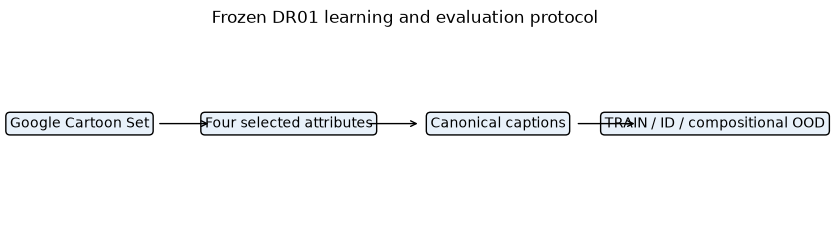

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 2.4))
ax.axis("off")
labels = [
    "Google Cartoon Set",
    "Four selected attributes",
    "Canonical captions",
    "TRAIN / ID / compositional OOD",
]
x_positions = [0.08, 0.35, 0.62, 0.9]
for x, label in zip(x_positions, labels, strict=True):
    ax.text(x, 0.5, label, ha="center", va="center", bbox={"boxstyle": "round", "facecolor": "#e8f1fa"})
for left, right in zip(x_positions[:-1], x_positions[1:], strict=True):
    ax.annotate("", xy=(right - 0.1, 0.5), xytext=(left + 0.1, 0.5), arrowprops={"arrowstyle": "->"})
ax.set_title("Frozen DR01 learning and evaluation protocol")
plt.show()

## Leakage safeguards and protocol summary

- Vocabulary construction uses TRAIN captions only.
- Split assignment and precedence are frozen before model selection.
- COMP_VAL supports development without opening FINAL_OOD for tuning.
- FINAL_OOD definitions are fixed and absent from TRAIN as combinations.
- Individual held-out values remain represented in TRAIN.

Together, these checks isolate compositional recombination while preserving ordinary lexical support.